# 05 · Symptom prediction (leak-free)

Visualises `src/symptom_prediction` output (run `python -m src.symptom_prediction.leakage_audit` and
`python -m src.symptom_prediction.run`).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pickle
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src.core import paths
from src.core.data import GROUPS, load_data, load_model_results, load_features

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"HC": "#2a9d8f", "AP": "#e76f51", "NAP": "#e9c46a"}

## Leakage audit of the v1 PANSS model

,threshold,selection,R2,r,p_R2
0,0.15,full sample (leaky),0.2416,0.5014,NaN
1,0.15,inside folds,-0.3269,-0.0511,NaN
2,0.20,full sample (leaky),0.3142,0.5644,NaN
3,0.20,inside folds,-0.2126,0.0187,NaN
4,0.25,full sample (leaky),0.1361,0.3697,NaN
5,0.25,inside folds,-0.3084,-0.2106,NaN
6,0.20,"leaky, permutation null (n=200)",0.1506,0.3629,0.1144


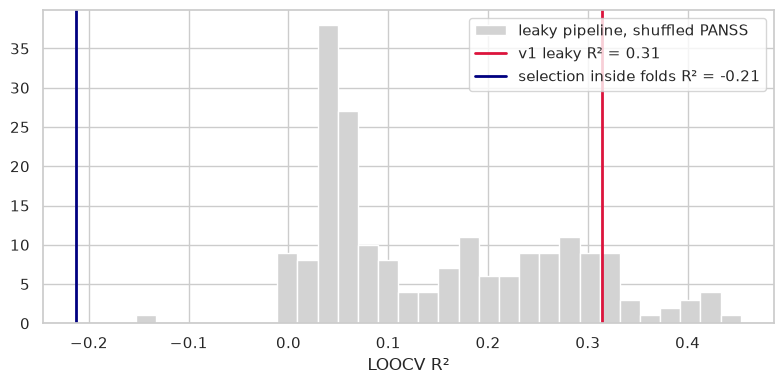

In [2]:
D = paths.DERIVED / "symptom_prediction"
L = pd.read_csv(D / "leakage_audit.csv"); null = pd.read_csv(D / "leakage_null.csv")
display(L.round(4))
leaky = L[(L.threshold == 0.2) & L.selection.str.startswith("full")].R2.item()
nested = L[(L.threshold == 0.2) & (L.selection == "inside folds")].R2.item()
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(null.R2, bins=30, color="lightgray", label="leaky pipeline, shuffled PANSS")
ax.axvline(leaky, color="crimson", lw=2, label=f"v1 leaky R² = {leaky:.2f}")
ax.axvline(nested, color="navy", lw=2, label=f"selection inside folds R² = {nested:.2f}")
ax.set_xlabel("LOOCV R²"); ax.legend()
plt.tight_layout(); plt.show()

## Model comparison

`r_within`: CV prediction vs truth after removing AP/NAP means (averaged over 5 repeats). Grey bar = 95th percentile
of the within-group permutation null; negative values are a CV shrinkage artefact shared by the null.

,target,features,n,n_features,r_within,R2,R2_group_only,p_perm,null_mean,null_95
0,PANSS,"FC edges (ridge, all)",92,4950,-0.297,-0.068,-0.035,0.617,-0.227,0.080
1,PANSS,FC edges (in-fold top-200),92,4950,-0.034,-0.256,-0.035,0.517,-0.040,0.150
2,PANSS,lag-1 FS edges (in-fold top-200),92,9900,-0.069,-0.300,-0.035,0.617,-0.033,0.172
3,PANSS,"GEC edges (ridge, SC mask)",92,8968,-0.326,-0.053,-0.035,0.701,-0.208,0.086
4,PANSS,FC network blocks (28),92,28,-0.333,-0.068,-0.035,0.448,-0.267,0.089
5,PANSS,HOI: O-info network compositions (168),92,168,-0.389,-0.038,-0.035,0.791,-0.264,0.049
6,PANSS,HOI + FC blocks (196),92,196,-0.392,-0.038,-0.035,0.796,-0.262,0.037
7,PANSS,HOI: nodal O-info (100),92,100,-0.382,-0.037,-0.035,0.726,-0.261,0.058
8,PANSS,Hierarchy: P_j + nodal irreversibility lag2 (200),92,200,-0.352,-0.037,-0.035,0.677,-0.232,0.062
9,PANSS,Perturbation: p2h noise + a-neg maps (200),92,200,-0.380,-0.038,-0.035,0.677,-0.282,0.031


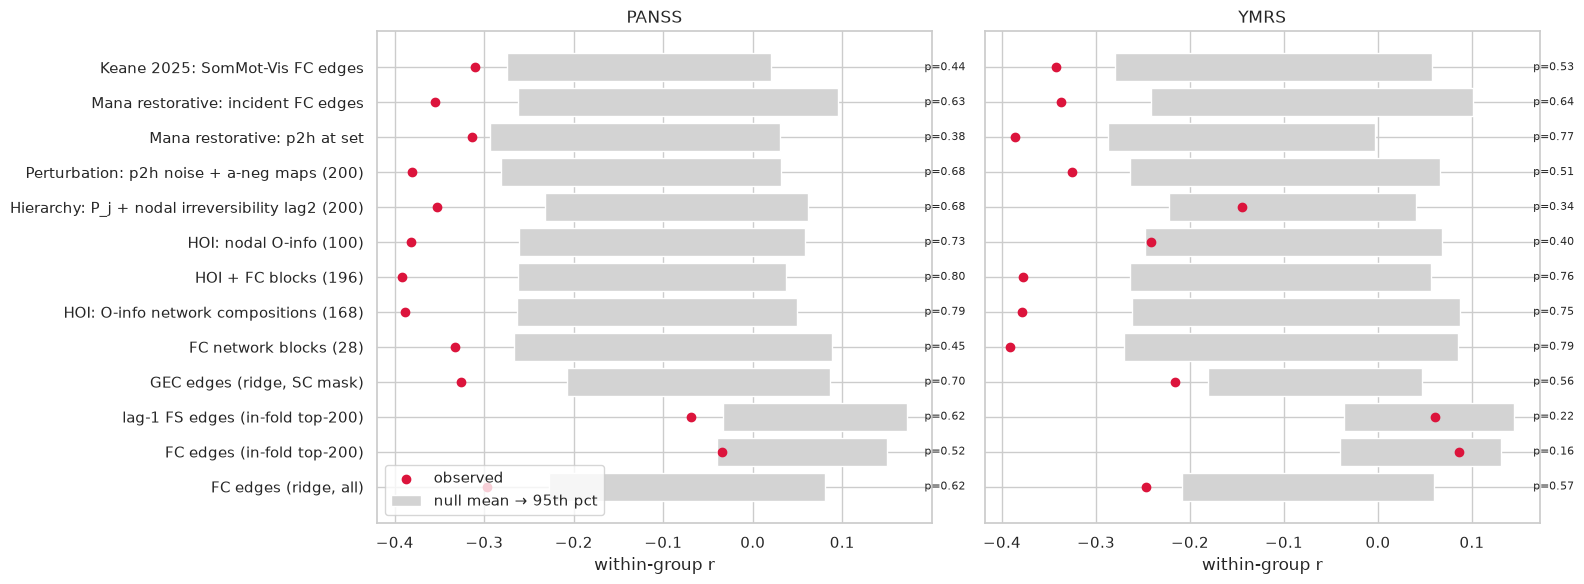

In [3]:
R = pd.read_csv(D / "model_comparison.csv")
display(R.round(3))
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, t in zip(axes, ("PANSS", "YMRS")):
    d = R[R.target == t].reset_index(drop=True)
    y = np.arange(len(d))
    ax.barh(y, d.null_95 - d.null_mean, left=d.null_mean, color="lightgray", label="null mean → 95th pct")
    ax.scatter(d.r_within, y, color="crimson", zorder=3, label="observed")
    for i, p in enumerate(d.p_perm): ax.text(max(d.r_within.max(), d.null_95.max()) + 0.02, i, f"p={p:.2f}", va="center", fontsize=8)
    ax.set_yticks(y); ax.set_yticklabels(d.features); ax.set_title(t); ax.set_xlabel("within-group r")
axes[0].legend(loc="lower left")
plt.tight_layout(); plt.show()